# Multiclass Classification

Our dataset consists of clinical data from patients who entered the hospital complaining of chest pain ("angina") during exercise.  The information collected includes:

* `age` : Age of the patient

* `sex` : Sex of the patient

* `cp` : Chest Pain type

    + Value 0: asymptomatic
    + Value 1: typical angina
    + Value 2: atypical angina
    + Value 3: non-anginal pain
   
    
* `trtbps` : resting blood pressure (in mm Hg)

* `chol` : cholesterol in mg/dl fetched via BMI sensor

* `restecg` : resting electrocardiographic results

    + Value 0: normal
    + Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
    + Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria

* `thalach` : maximum heart rate achieved during exercise

* `output` : the doctor's diagnosis of whether the patient is at risk for a heart attack
    + 0 = not at risk of heart attack
    + 1 = at risk of heart attack

In [1]:
## library imports here
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from plotnine import *

First we'll create binary variables for each class.

In [2]:
ha = pd.read_csv("https://www.dropbox.com/s/aohbr6yb9ifmc8w/heart_attack.csv?dl=1")

ha["cp_is_3"] = ((ha["cp"] == 3) * 1)
ha["cp_is_2"] = ((ha["cp"] == 2) * 1)
ha["cp_is_1"] = ((ha["cp"] == 1) * 1)
ha["cp_is_0"] = ((ha["cp"] == 0) * 1)

# strings for the purposes of plotting
ha["cp"] = ha["cp"].astype("str")
ha

,age,sex,cp,trtbps,chol,restecg,thalach,output,cp_is_3,cp_is_2,cp_is_1,cp_is_0
0,63,1,3,145,233,0,150,1,1,0,0,0
1,37,1,2,130,250,1,187,1,0,1,0,0
2,56,1,1,120,236,1,178,1,0,0,1,0
3,57,0,0,120,354,1,163,1,0,0,0,1
4,57,1,0,140,192,1,148,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
268,59,1,0,164,176,0,90,0,0,0,0,1
269,57,0,0,140,241,1,123,0,0,0,0,1
270,45,1,3,110,264,1,132,0,1,0,0,0
271,68,1,0,144,193,1,141,0,0,0,0,1


The target is `cp` which has 4 categories. How common is each category?

In [3]:
ha["cp"].value_counts().sort_index()

cp
0    128
1     44
2     81
3     20
Name: count, dtype: int64

Let's consider as predictors: `trtbps`, `chol`, `age`.

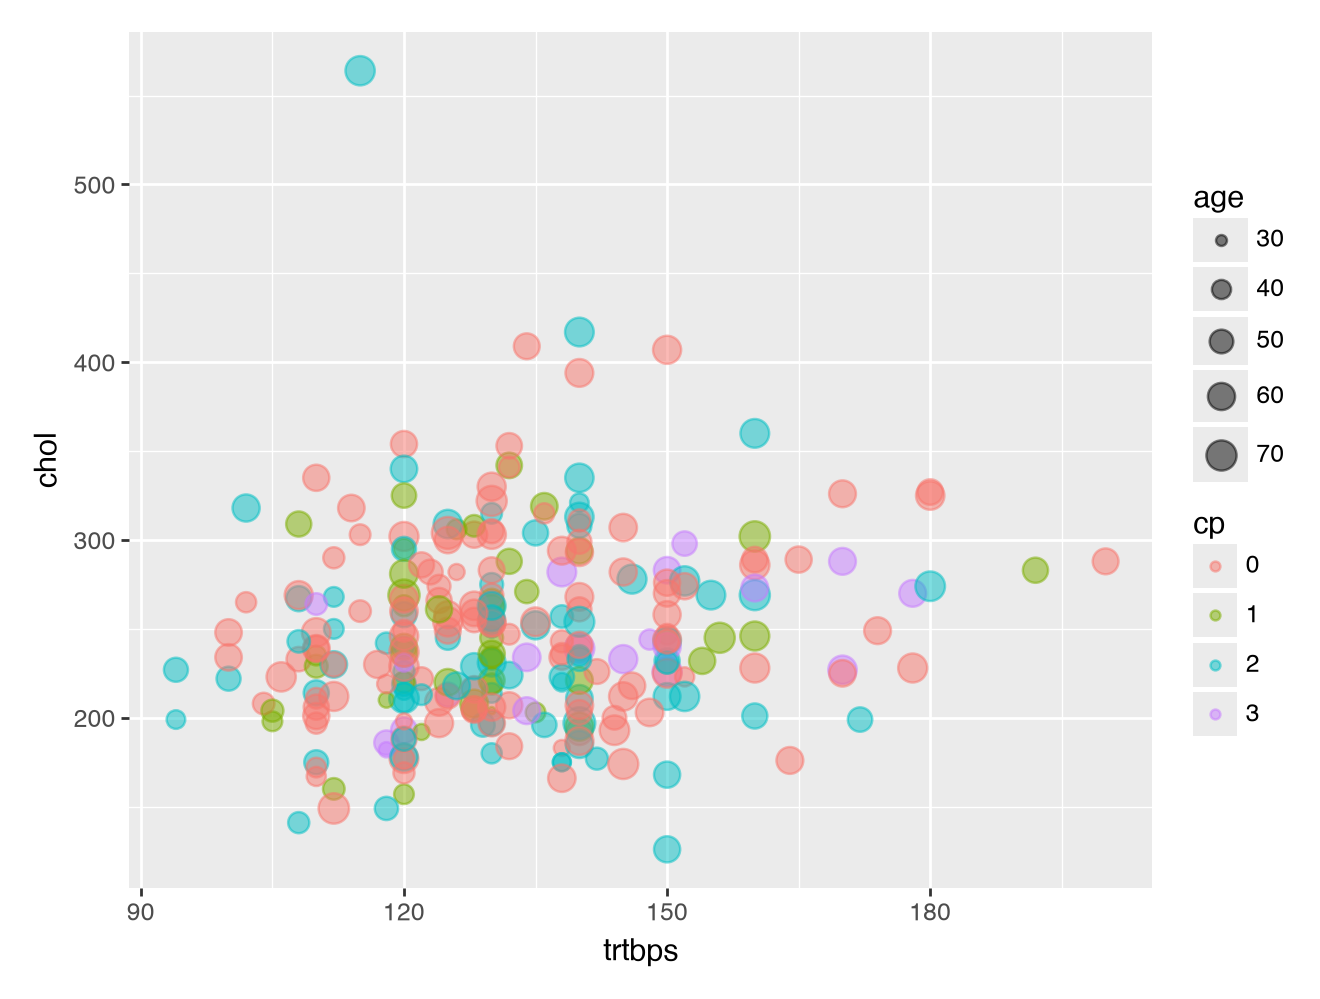

In [4]:
(ggplot(ha, aes(x="trtbps", y="chol", size = "age", color="cp"))
+ geom_point(alpha = 0.5))

## Q1: A Natural Multiclass Model: k-nearest neighbors

Fit a multiclass 10-nearest neighbors model. Output the predicted class probabilities and plot the predicted classes for the training data. Estimate the test:

- accuracy
- macro precision, recall, and F1 scores
- precision, recall, and F1 score for each class. You will likely get some weird values; can you explain why?


In [5]:
import numpy as np
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_predict

X = ha[['trtbps', 'chol', 'age']]
y = ha['cp']

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=10))
])

knn_pipeline.fit(X, y)
knn_probs = knn_pipeline.predict_proba(X)
knn_preds = knn_pipeline.predict(X)

ha['knn_preds'] = knn_preds.astype(str)

plot_knn = (
    ggplot(ha, aes(x='trtbps', y='chol', size='age', color='knn_preds'))
    + geom_point(alpha=0.5)
    + labs(title="Q1: KNN (k=10) Predicted Classes", color="Predicted CP")
)
print(plot_knn)
cv_preds = cross_val_predict(knn_pipeline, X, y, cv=5)
print("\nClassification Report (Estimated via 5-Fold Cross Validation):")
print(classification_report(y, cv_preds, zero_division=0))


<ggplot: (640 x 480)>

Classification Report (Estimated via 5-Fold Cross Validation):
              precision    recall  f1-score   support

           0       0.46      0.75      0.57       128
           1       0.15      0.05      0.07        44
           2       0.29      0.19      0.23        81
           3       0.00      0.00      0.00        20

    accuracy                           0.41       273
   macro avg       0.23      0.25      0.22       273
weighted avg       0.33      0.41      0.35       273



## Q2:  OvR for Class 3



Fit a logistic regression model for predicting Class 3. Output the predicted class probabilities (Class 3 or not) and plot the predicted classes (Class 3 or not) for the training data. Estimate the test:

- precision, recall, and F1 score for class 3

In [6]:
import numpy as np
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_predict

X = ha[['trtbps', 'chol', 'age']]
y_3 = ha['cp_is_3']

log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression())
])

log_reg_pipeline.fit(X, y_3)
ha['pred_3_prob'] = log_reg_pipeline.predict_proba(X)[:, 1]
ha['pred_3_class'] = log_reg_pipeline.predict(X)

plot_q2 = (
    ggplot(ha, aes(x='trtbps', y='chol', size='age', color='factor(pred_3_class)'))
    + geom_point(alpha=0.5)
    + labs(title="Q2: Predicted Class 3 (1=Yes, 0=No)", color="Pred Class 3")
)
print(plot_q2)

cv_preds_3 = cross_val_predict(log_reg_pipeline, X, y_3, cv=5)
print("\nClass 3 OvR Classification Report (5-Fold CV):")
print(classification_report(y_3, cv_preds_3, zero_division=0))

<ggplot: (640 x 480)>

Class 3 OvR Classification Report (5-Fold CV):
              precision    recall  f1-score   support

           0       0.93      1.00      0.96       253
           1       0.00      0.00      0.00        20

    accuracy                           0.93       273
   macro avg       0.46      0.50      0.48       273
weighted avg       0.86      0.93      0.89       273



## Q3: OvR - Other classes.

Repeat Q2 for each of the other three `cp` categories.  Which category was the OvR approach best at distinguishing?

In [7]:
import numpy as np
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_predict

X = ha[['trtbps', 'chol', 'age']]

log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression())
])


for cp_val in [0, 1, 2]:

    y_class = ha[f'cp_is_{cp_val}']


    cv_preds_class = cross_val_predict(log_reg_pipeline, X, y_class, cv=5)

    print(f"==================================================")
    print(f"Classification Report for Class {cp_val} vs All Others (5-Fold CV):")
    print(f"==================================================")
    print(classification_report(y_class, cv_preds_class, zero_division=0))
    print("\n")

Classification Report for Class 0 vs All Others (5-Fold CV):
              precision    recall  f1-score   support

           0       0.56      0.66      0.60       145
           1       0.51      0.41      0.46       128

    accuracy                           0.54       273
   macro avg       0.54      0.53      0.53       273
weighted avg       0.54      0.54      0.54       273



Classification Report for Class 1 vs All Others (5-Fold CV):
              precision    recall  f1-score   support

           0       0.84      1.00      0.91       229
           1       0.00      0.00      0.00        44

    accuracy                           0.84       273
   macro avg       0.42      0.50      0.46       273
weighted avg       0.70      0.84      0.77       273



Classification Report for Class 2 vs All Others (5-Fold CV):
              precision    recall  f1-score   support

           0       0.70      1.00      0.83       192
           1       0.00      0.00      0.00       

## Q4: OvO

Reduce your dataset to only the `0` and `1` types of chest pain.

Then, fit a Logistic Regression to predict between the two groups, and estimate the ROC-AUC.  


In [8]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

ha_01 = ha[ha['cp'].isin(['0', '1'])].copy()

X_01 = ha_01[['trtbps', 'chol', 'age']]
y_01 = (ha_01['cp'] == '1').astype(int) # Target: 1 if cp is '1', else 0 (which is '0')

log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression())
])

log_reg_pipeline.fit(X_01, y_01)

cv_probs_01 = cross_val_predict(log_reg_pipeline, X_01, y_01, cv=5, method='predict_proba')[:, 1]
roc_auc_01 = roc_auc_score(y_01, cv_probs_01)

print(f"Estimated 5-Fold CV ROC-AUC for Class 0 vs Class 1: {roc_auc_01:.4f}")

Estimated 5-Fold CV ROC-AUC for Class 0 vs Class 1: 0.5978


## Q5: OvO

Repeat Q4 comparing category `0` to `2`, and again to compare category `0` to `3`.  Which pair was the OvO approach best at distinguishing?

In [9]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

# Pipeline definition
log_reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression())
])

for other_class in ['2', '3']:
    ha_sub = ha[ha['cp'].isin(['0', other_class])].copy()
    X_sub = ha_sub[['trtbps', 'chol', 'age']]
    y_sub = (ha_sub['cp'] == other_class).astype(int)
    cv_probs_sub = cross_val_predict(log_reg_pipeline, X_sub, y_sub, cv=5, method='predict_proba')[:, 1]
    roc_auc_sub = roc_auc_score(y_sub, cv_probs_sub)
    print(f"Estimated 5-Fold CV ROC-AUC for Class 0 vs Class {other_class}: {roc_auc_sub:.4f}")

Estimated 5-Fold CV ROC-AUC for Class 0 vs Class 2: 0.5484
Estimated 5-Fold CV ROC-AUC for Class 0 vs Class 3: 0.5523
